#### Notebook setup and imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# Integrate a single dynamical system

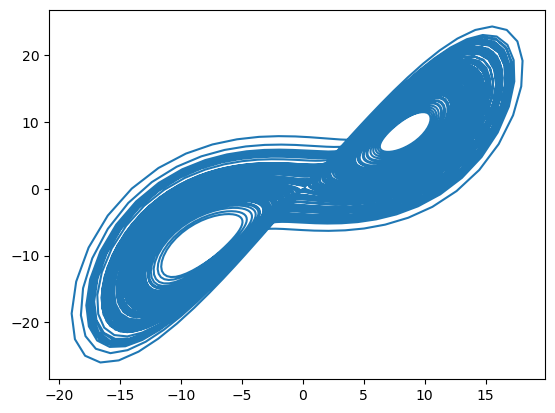

In [2]:
from dysts.flows import Lorenz, Hadley

## Load and simulate an attractor
model = Lorenz()
sol = model.make_trajectory(10000, resample=True)
plt.figure()
plt.plot(sol[:, 0], sol[:, 1])

We now consider some of the different keyword arguments that can be passed to the `make_trajectory` function. In order to integrate a system with noise, the package `sdeint` must be installed. This can be done by running `pip install sdeint` in the terminal.

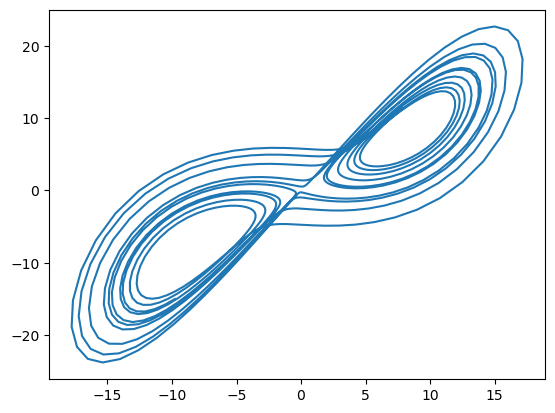

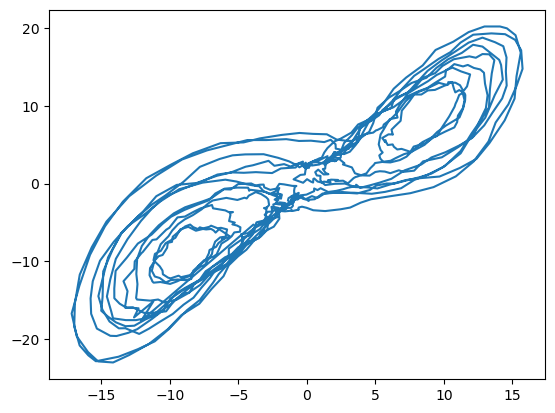

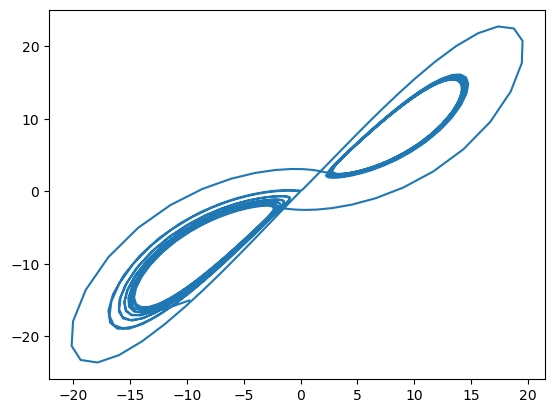

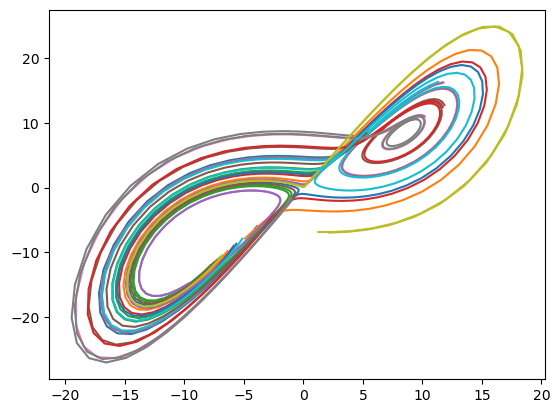

In [3]:
from dysts.flows import *

## Load and simulate an attractor
model = Lorenz()
sol = model.make_trajectory(1000, resample=True)
plt.figure()
plt.plot(sol[:, 0], sol[:, 1])

## Simulate with noise
sol = model.make_trajectory(1000, resample=True, noise=0.2)
plt.figure()
plt.plot(sol[:, 0], sol[:, 1])

## Change a parameter value
model.sigma *= 2
sol = model.make_trajectory(1000, resample=True)
plt.figure()
plt.plot(sol[:, 0], sol[:, 1])

# ## Solve for multiple initial conditions
model = Lorenz()
model.ic = model.ic[None, :] * np.random.random(20)[:, None]
sol = model.make_trajectory(100, resample=True)
plt.figure()
plt.plot(sol[..., 0].T, sol[..., 1].T);

We also consider utilities for generating multiple trajectories from all of the dynamical systems in the dataset

/Users/william/program_repos/dysts/dysts/base.py:287: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate trajectories from the raw system.
  warnings.warn(
/Users/william/program_repos/dysts/dysts/base.py:287: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate trajectories from the raw system.
  warnings.warn(
/Users/william/program_repos/dysts/dysts/base.py:287: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate trajectories from the raw system.
  warnings.warn(
/Users/william/program_repos/dysts/dysts/base.py:287: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate

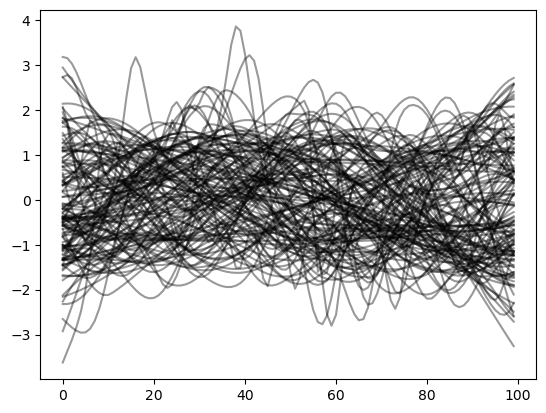

In [8]:
from dysts.systems import make_trajectory_ensemble
from dysts.utils import standardize_ts

all_out = make_trajectory_ensemble(100, resample=True)
for attractor_name in all_out:
    plt.plot(standardize_ts(all_out[attractor_name])[:, 0], 'k', alpha=0.4)

# View all attractors

+ We use the batch integration function to generate trajectories for all of the dynamical systems in the dataset
+ Each attractor is standardized and shown from a random viewing angle, drawn reproducibly from a fixed seed and the system's name

/Users/william/program_repos/dysts/dysts/base.py:349: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate trajectories from the raw system.
  warnings.warn(
/Users/william/program_repos/dysts/dysts/base.py:349: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate trajectories from the raw system.
  warnings.warn(
/Users/william/program_repos/dysts/dysts/base.py:349: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate trajectories from the raw system.
  warnings.warn(
/Users/william/program_repos/dysts/dysts/base.py:349: UserWarning: This system has at least one unbounded variable, which has been mapped to a bounded domain. Pass argument postprocess=False in order to generate

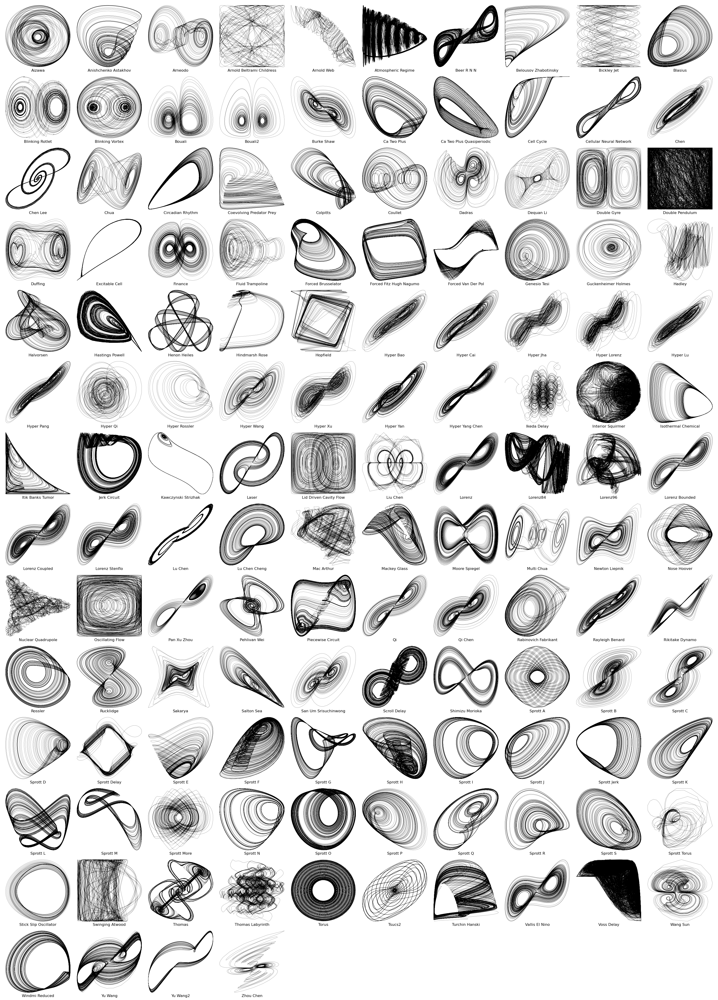

In [3]:
from dysts.systems import make_trajectory_ensemble

## Integrate all trajectories
all_trajectories = make_trajectory_ensemble(10000, method="Radau", resample=True)

## Show each attractor from a random viewing angle. Each system's rotation is drawn
## from a generator seeded by (SEED, system name), so every system gets its own view,
## the gallery is reproducible, and adding a system does not change anyone else's view.
SEED = 0
import zlib
def random_rotation(name, dim, seed=SEED):
    """A uniformly random (Haar) rotation matrix, unique to each system name"""
    rng = np.random.default_rng([seed, zlib.crc32(name.encode())])
    q, r = np.linalg.qr(rng.standard_normal((dim, dim)))
    q *= np.sign(np.diag(r))  # make the distribution uniform over rotations
    if np.linalg.det(q) < 0:  # proper rotation, not a reflection
        q[:, 0] *= -1
    return q

def random_view(name, sol):
    """Standardize each coordinate, rotate, and keep the first two rotated axes"""
    sol = (sol - sol.mean(axis=0)) / sol.std(axis=0)
    return sol @ random_rotation(name, sol.shape[1])[:, :2]

num_cols = 10
num_rows = int(np.ceil(len(all_trajectories) / num_cols))
fig = plt.figure(figsize=(num_cols*4, num_rows*4))

gs = plt.matplotlib.gridspec.GridSpec(num_rows, num_cols)
gs.update(wspace=0.0, hspace=0.05) 

## Helper function to split camel case into words
import re
def split_string(string):
    return re.sub(r'([A-Z])', r' \1', string).strip()

for i, attractor_name in enumerate(all_trajectories):
    
    sol = random_view(attractor_name, all_trajectories[attractor_name])
    
    plt.subplot(gs[i])
    plt.plot(sol[:, 0], sol[:, 1], 'k', linewidth=0.25)
    plt.title(split_string(attractor_name), y=-0.05)
    plt.gca().axis('off')

## Visualize all attractors
# import degas as dg
# dg.better_savefig("./dysts/data/all_attractors.jpg", dpi=150)
# dg.better_savefig("./dysts/data/all_attractors.png", dpi=150)

# Discrete-time maps

+ The `dysts.maps` submodule implements discrete maps

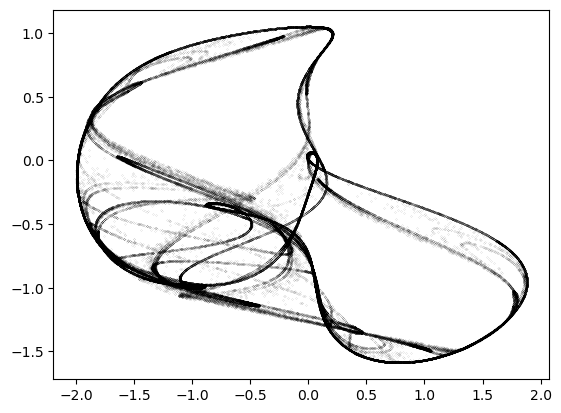

In [11]:
from dysts.maps import DeJong
sol =  DeJong().make_trajectory(100000)
plt.figure()
plt.plot(sol[..., 0], sol[..., 1], '.k', markersize=0.1)

## Evolve a group of initial conditions

+ We can use the `dysts.maps` function to evolve a group of initial conditions under a single map

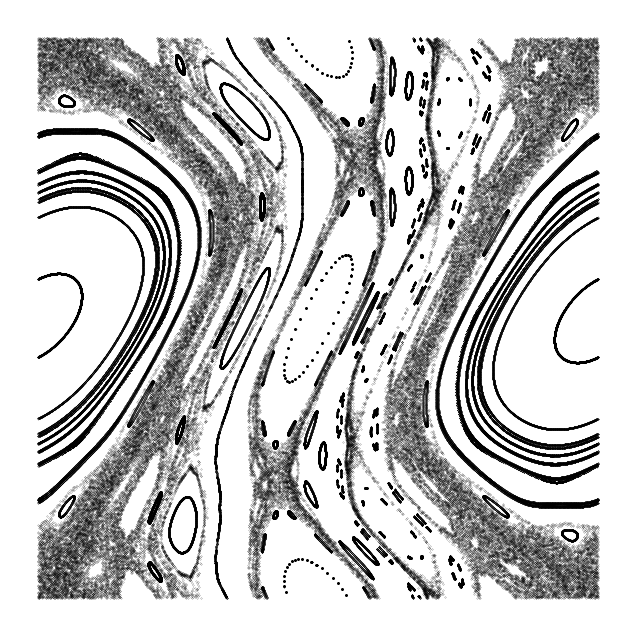

In [24]:
from dysts.maps import Chirikov

## Phase space for Chirikov standard map
model = Chirikov()
model.ic =  2 * np.pi * np.random.random((40, 2)) # uniform random initial conditions
sol = model.make_trajectory(6000)

plt.figure(figsize=(8, 8))
plt.plot(np.mod(sol.T[0], 2*np.pi), np.mod(sol.T[1], 2*np.pi), '.k', markersize=0.3, alpha=0.9);
plt.axis("off")
plt.gca().set_aspect("equal")


# Precomputed time series datasets

+ The library also includes a number of precomputed time series datasets. These datasets are useful for testing and benchmarking algorithms on consistent data

+ Due to install size considerations, precomputed datasets require installing a large, external data repository

```bash
    pip install git+https://github.com/williamgilpin/dysts_data
```

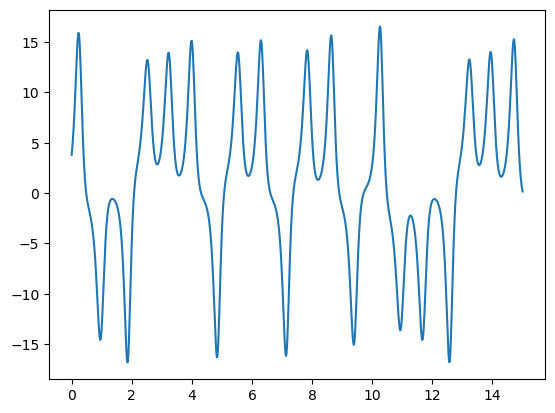

In [5]:
from dysts.datasets import load_dataset

## Load train trajectories
plt.figure()
data = load_dataset(subsets="train", data_format="pandas", standardize=False)
plt.plot(np.array(data.loc["Lorenz"][["time"]]), np.array(data.loc["Lorenz"][["values"]]))

### Load a specific univariate dataset with train/test split

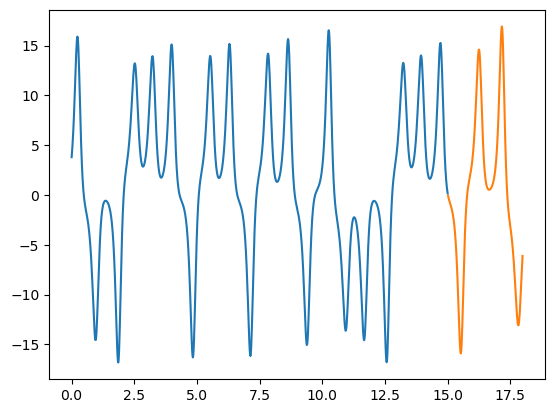

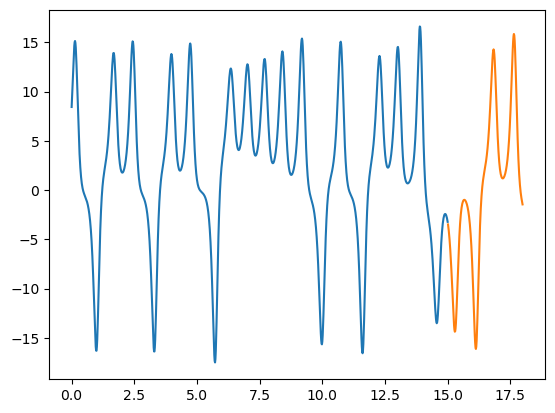

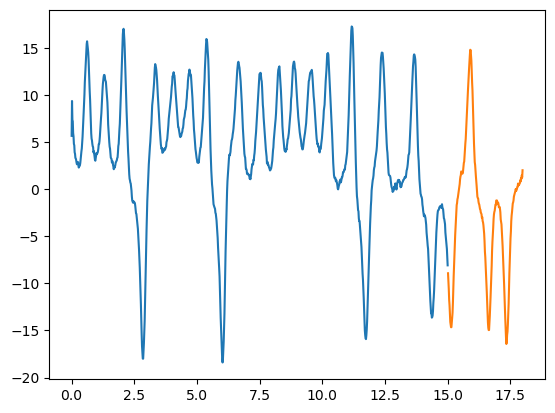

In [6]:
## Load train trajectories
plt.figure()
data = load_dataset(subsets="train", data_format="pandas", standardize=False)
plt.plot(np.array(data.loc["Lorenz"][["time"]]), np.array(data.loc["Lorenz"][["values"]]))

data = load_dataset(subsets="train_val", data_format="pandas", standardize=False)
plt.plot(np.array(data.loc["Lorenz"][["time"]]), np.array(data.loc["Lorenz"][["values"]]))


## Load test trajectories
plt.figure()
data = load_dataset(subsets="test", data_format="pandas", standardize=False)
plt.plot(np.array(data.loc["Lorenz"][["time"]]), np.array(data.loc["Lorenz"][["values"]]))

data = load_dataset(subsets="test_val", data_format="pandas", standardize=False)
plt.plot(np.array(data.loc["Lorenz"][["time"]]), np.array(data.loc["Lorenz"][["values"]]))



## Load trajectories with noise
plt.figure()
data = load_dataset(subsets="test", data_format="pandas", standardize=False, noise=True)
plt.plot(np.array(data.loc["Lorenz"][["time"]]), np.array(data.loc["Lorenz"][["values"]]))

data = load_dataset(subsets="test_val", data_format="pandas", standardize=False, noise=True)
plt.plot(np.array(data.loc["Lorenz"][["time"]]), np.array(data.loc["Lorenz"][["values"]]))


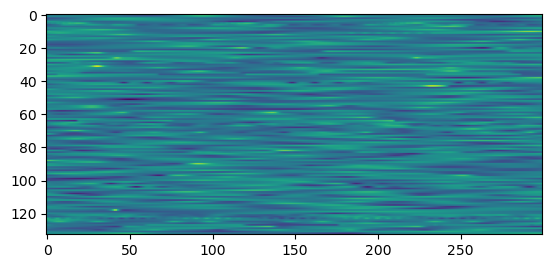

In [10]:
## All univariate datasets

data = load_dataset(data_format="numpy", standardize=True)
plt.imshow(data[:, :300])

### Multivariate datasets with train/test split

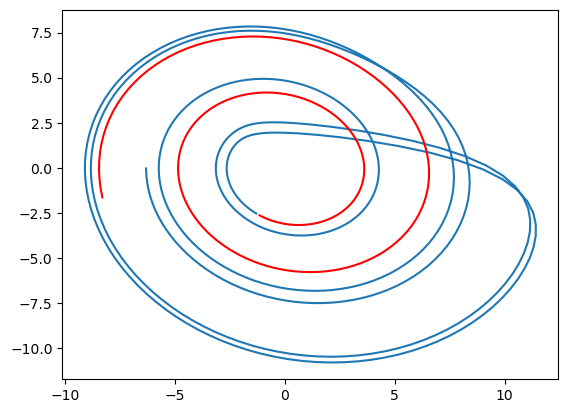

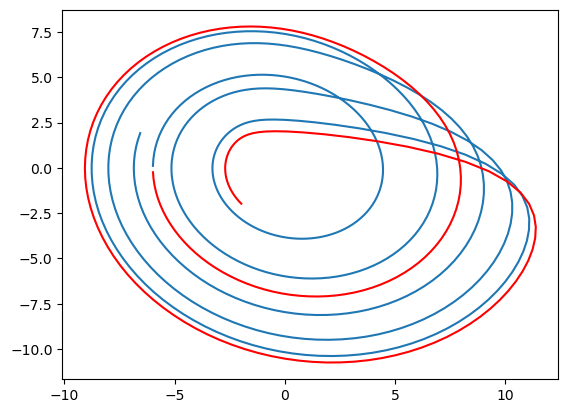

In [7]:
plt.figure()
data = load_dataset(subsets="train", univariate=False, standardize=False)
plt.plot(*data.dataset["Rossler"]["values"].T[:2, -500:])

data = load_dataset(subsets="train_val", univariate=False, standardize=False)
plt.plot(*data.dataset["Rossler"]["values"].T[:2, :500], 'r')


plt.figure()
data = load_dataset(subsets="test", univariate=False, standardize=False)
plt.plot(*data.dataset["Rossler"]["values"].T[:2, -500:])

data = load_dataset(subsets="test_val", univariate=False, standardize=False)
plt.plot(*data.dataset["Rossler"]["values"].T[:2, :500], 'r')

### Load precomputed trajectories for a single system

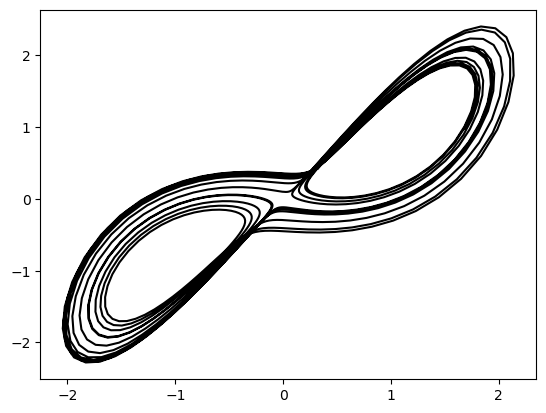

In [4]:
from dysts.flows import *

eq = Lorenz()

tpts, sol = eq.load_trajectory(
    subsets="test", 
    noise=False, 
    granularity="fine", 
    standardize=True, 
    return_times=True
)

plt.plot(sol[:, 0], sol[:, 1], 'k')